In [33]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import seaborn as sns
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [8]:
test_data = pd.read_csv('/Users/phillipphi/Desktop/IDX Exchange/test_data.csv')
training_data = pd.read_csv('/Users/phillipphi/Desktop/IDX Exchange/training_data.csv')

training_x = training_data.drop('ClosePrice', axis=1)
training_y = training_data.ClosePrice

test_x = test_data.drop('ClosePrice', axis=1)
test_y = test_data.ClosePrice

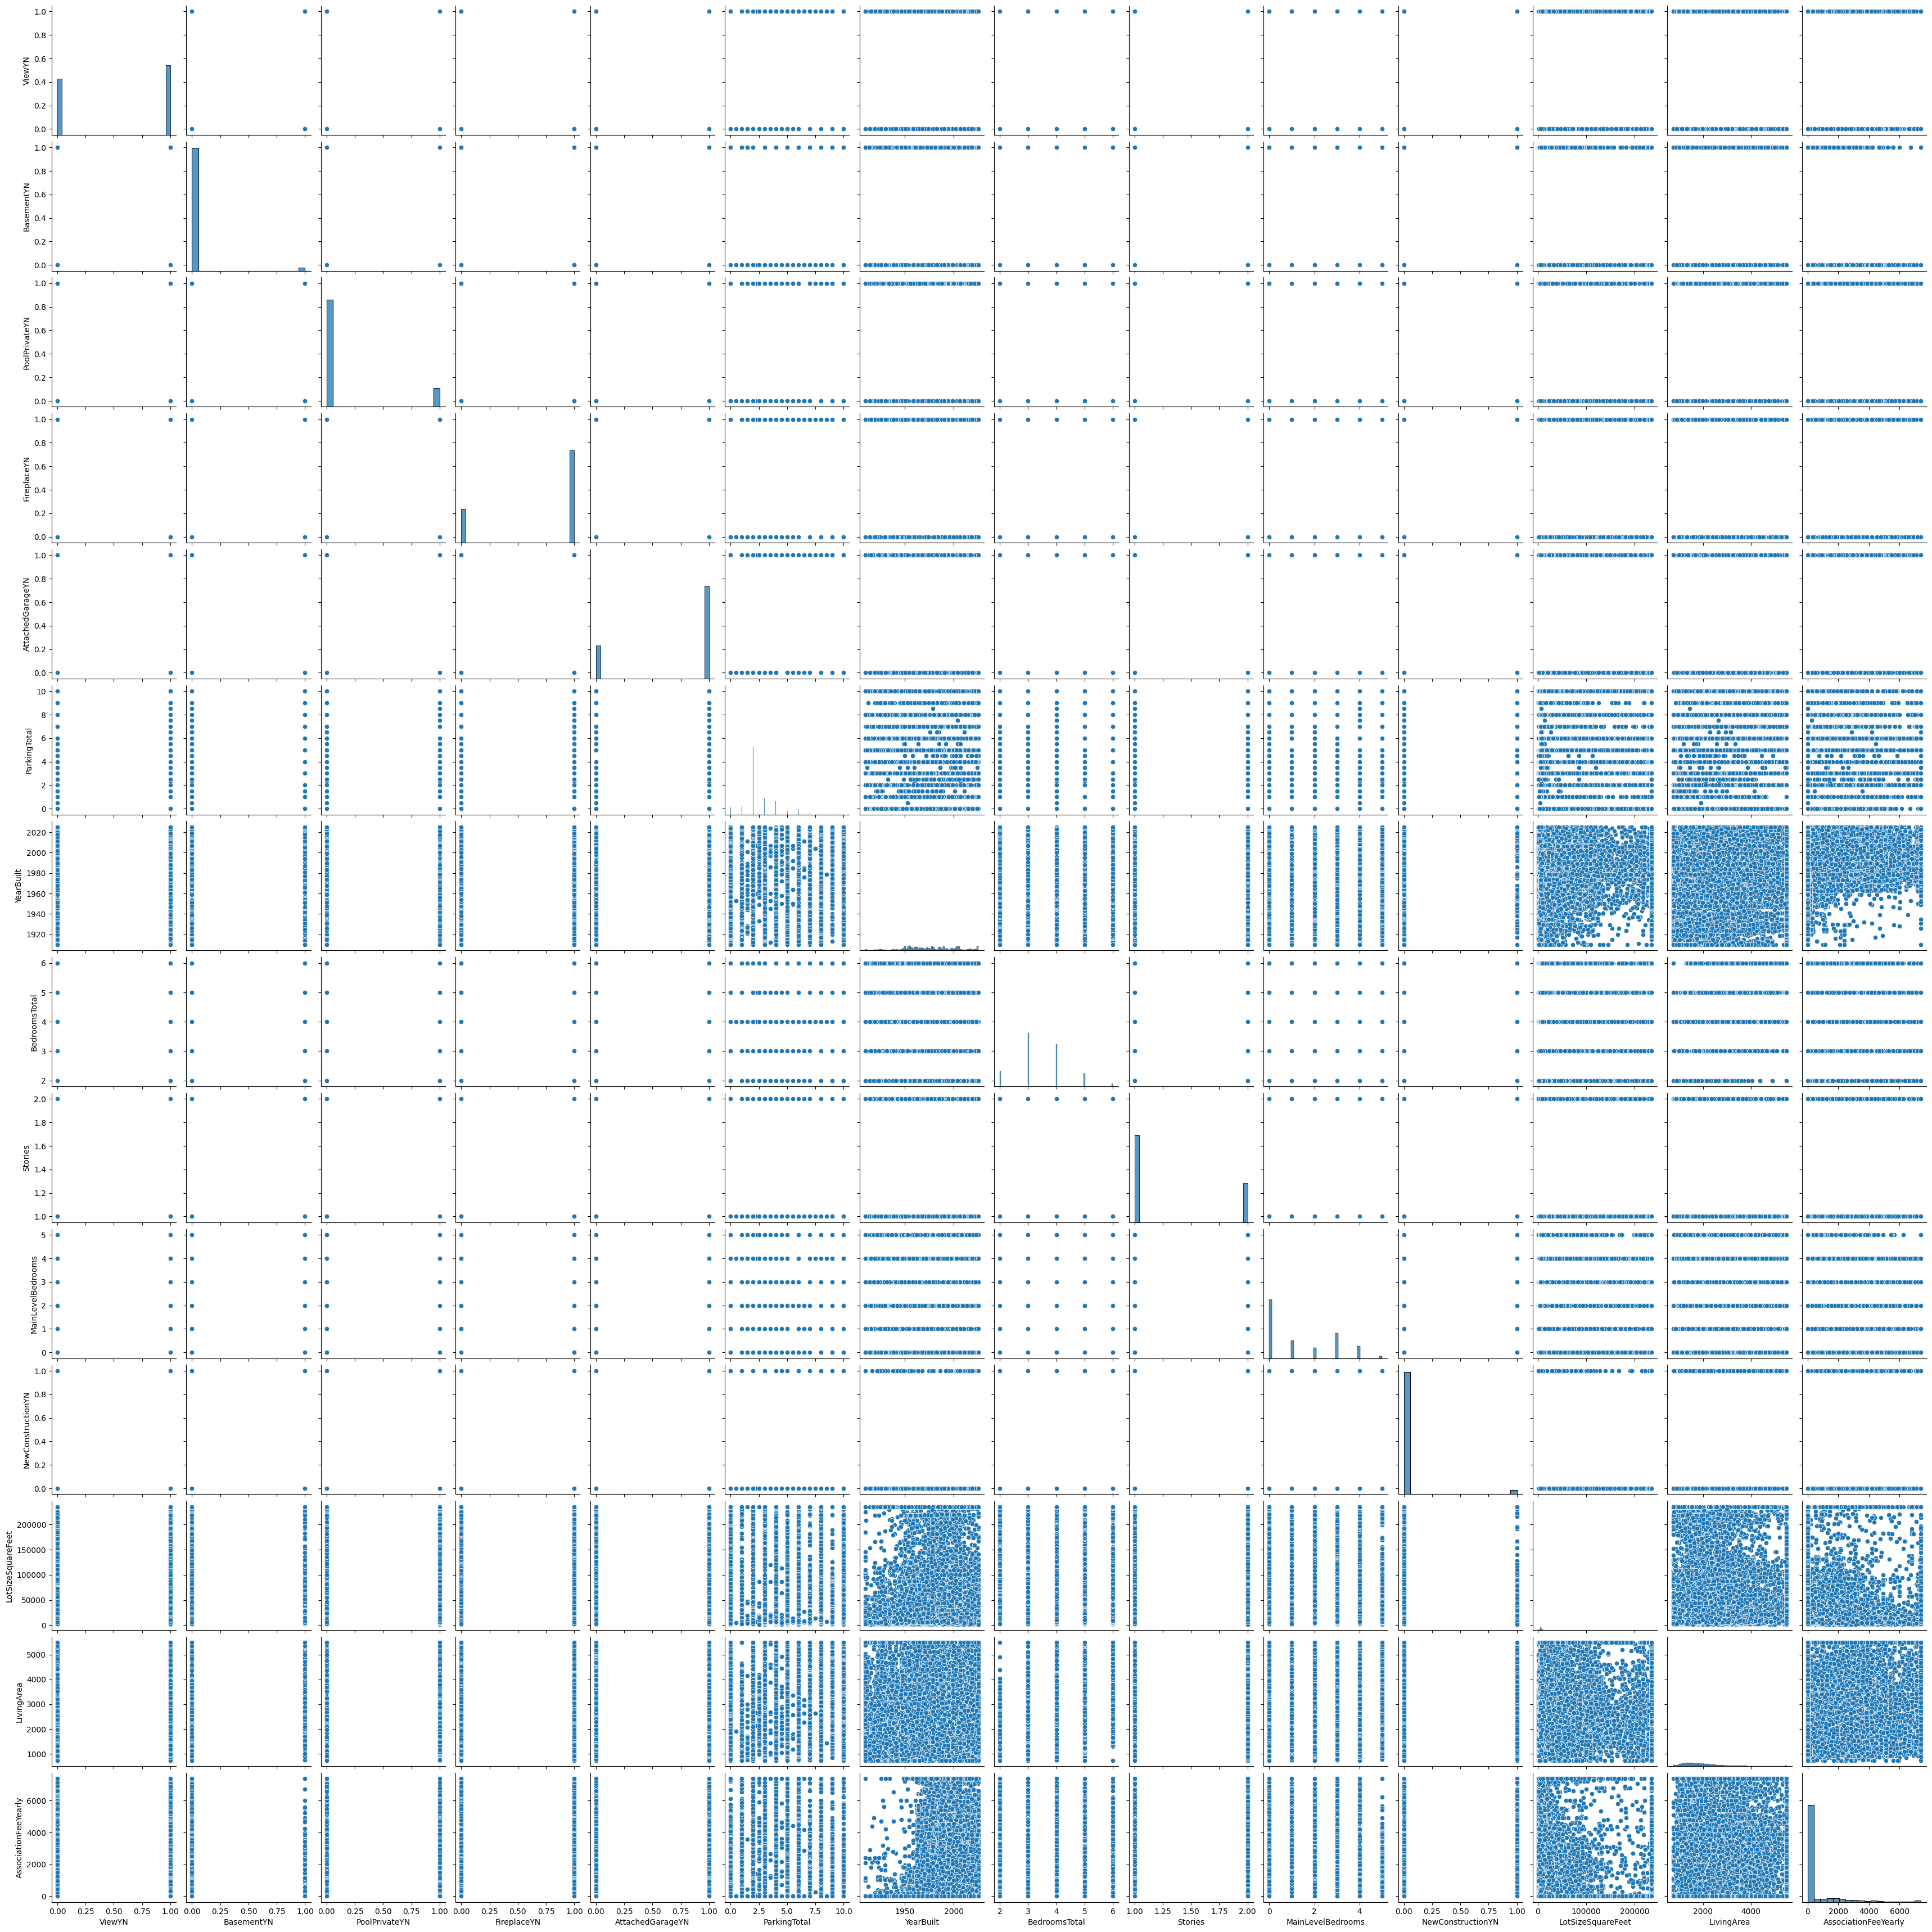

In [ ]:
# creates a visual of the pairwise relationships in the training data

sns.pairplot(training_x)
plt.show()

In [41]:
# summary of the baseline model performance
# uses statsmodels to show a more cohesive summary of the regression results

stats_lm = smf.ols(formula='training_y ~ training_x', data=training_data).fit()
print(stats_lm.summary())

                            OLS Regression Results                            
Dep. Variable:             training_y   R-squared:                       0.493
Model:                            OLS   Adj. R-squared:                  0.493
Method:                 Least Squares   F-statistic:                     7811.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:33:49   Log-Likelihood:            -1.6725e+06
No. Observations:              112459   AIC:                         3.345e+06
Df Residuals:                  112444   BIC:                         3.345e+06
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept        1.98e+07   2.02e+05     98.

In [30]:
# uses scikit-learn's LinearRegression to create the model
lm = LinearRegression()
lm.fit(training_x, training_y)

train_pred = lm.predict(training_x)
r2 = r2_score(training_y, train_pred)
print(r2)

test_pred = lm.predict(test_x)
r2_test = r2_score(test_y, test_pred)
print(r2_test)

0.49304503872929895
0.5063789869061331


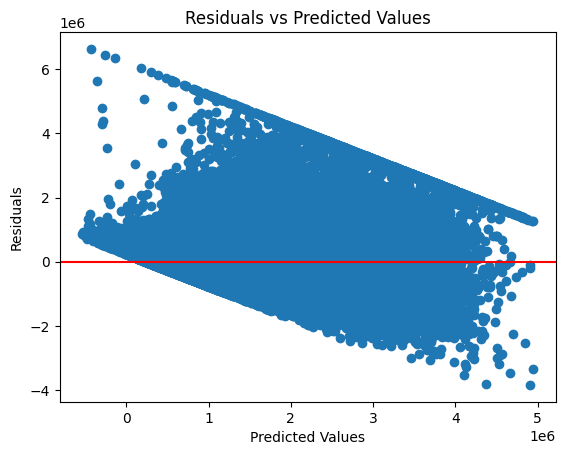

In [26]:
residuals = training_y - train_pred
plt.scatter(train_pred, residuals)
plt.axhline(0, color='red')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Values')
plt.show()

In [ ]:
# obtains the VIF of every feature

vif_data = pd.DataFrame()
vif_data["feature"] = training_x.columns
vif_data["VIF"] = [variance_inflation_factor(training_x.values, i) for i in range(training_x.shape[1])]
vif_data

,feature,VIF
0,ViewYN,2.540937
1,BasementYN,1.048474
2,PoolPrivateYN,1.334654
3,FireplaceYN,4.459113
4,AttachedGarageYN,4.264594
5,ParkingTotal,3.826901
6,YearBuilt,24.892977
7,BedroomsTotal,34.654186
8,Stories,12.599547
9,MainLevelBedrooms,2.205236


In [47]:
training_x2 = training_x.copy()
training_x2 = training_x2.drop(columns=["YearBuilt", "BedroomsTotal"])

stats_lm_v2 = smf.ols(formula='training_y ~ training_x2', data=training_data).fit()
print(stats_lm_v2.summary())

                            OLS Regression Results                            
Dep. Variable:             training_y   R-squared:                       0.451
Model:                            OLS   Adj. R-squared:                  0.451
Method:                 Least Squares   F-statistic:                     7701.
Date:                Sat, 17 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:34:57   Log-Likelihood:            -1.6770e+06
No. Observations:              112459   AIC:                         3.354e+06
Df Residuals:                  112446   BIC:                         3.354e+06
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept        4.876e+05   8875.695     